# 01. Khám phá và làm sạch dữ liệu (EDA)

**Mục tiêu học:** biết nhìn một bộ dữ liệu thật trước khi mô hình hoá; hiểu vì sao phải làm sạch, vì sao dùng `log(giá)`.

**Cách học:** trước khi chạy mỗi cell, hãy **tự dự đoán** kết quả (ghi ra giấy), chạy rồi so sánh. Cuối notebook có bài tập.

**Nội dung**
1. Nhìn tổng quan dữ liệu thô
2. Làm sạch từng bước và đo tác động
3. Phân phối của giá, và vì sao dùng log
4. Giá phụ thuộc vào tuổi xe và số km thế nào
5. Giá theo hãng và các thuộc tính phân loại
6. Tương quan và đa cộng tuyến
7. Phát hiện bất thường
8. Tóm tắt những gì rút ra

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score

from used_car_price.config import FEATURES, CATEGORICAL, NUMERIC, TARGET, RANDOM_STATE, RAW_PATH, TEST_SIZE
from used_car_price.data import load_data
from used_car_price.features import build_preprocessor
from used_car_price.train import log_target
from used_car_price.metrics import evaluate

pd.set_option("display.max_columns", 30); pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (7, 4.2)

## 1. Nhìn tổng quan dữ liệu thô

In [2]:
raw = pd.read_csv(RAW_PATH)
print("Kích thước:", raw.shape)
display(raw.head())
print("\nKiểu dữ liệu và số giá trị thiếu:")
display(pd.DataFrame({"kiểu": raw.dtypes, "thiếu": raw.isna().sum(), "% thiếu": (raw.isna().mean()*100).round(1),
                      "số giá trị khác nhau": raw.nunique()}))

Kích thước: (3226, 12)


,listing_id,brand,model,year,gearbox,fuel,province,origin,seats,km,price_million,crawled_at
0,7024368,Toyota,Fortuner,2011,tự động,xăng,Hà Nội,trong nước,7.0,110000.0,298.0,2026-10-08
1,7023951,Mazda,3,2023,tự động,xăng,Hà Nội,trong nước,5.0,10000.0,529.0,2026-10-08
2,7024359,VinFast,VF6,2025,tự động,điện,Hà Nội,trong nước,5.0,NaN,539.0,2026-10-08
3,7024345,Toyota,Innova,2019,số sàn,xăng,Hà Nội,trong nước,8.0,NaN,389.0,2026-10-08
4,6903360,Ford,Everest,2020,tự động,dầu,Hà Nội,nhập khẩu,7.0,NaN,695.0,2026-10-08



Kiểu dữ liệu và số giá trị thiếu:


,kiểu,thiếu,% thiếu,số giá trị khác nhau
listing_id,int64,0,0.0,3226
brand,str,0,0.0,49
model,str,2,0.1,257
year,int64,0,0.0,28
gearbox,str,0,0.0,2
fuel,str,0,0.0,4
province,str,0,0.0,45
origin,str,0,0.0,2
seats,float64,1,0.0,14
km,float64,346,10.7,416


**Câu hỏi để suy nghĩ:**
- Cột nào thiếu dữ liệu? Vì sao có thể thiếu (gợi ý: crawler chỉ đọc phần mô tả ngắn của tin)?
- Cột nào có quá nhiều giá trị khác nhau (high cardinality)? Điều này ảnh hưởng gì đến one-hot encoding?

In [3]:
display(raw[["year", "seats", "km", "price_million"]].describe().round(1))

,year,seats,km,price_million
count,3226.0,3225.0,2880.0,3226.0
mean,2019.9,5.7,63023.1,5907.3
std,4.5,1.5,71124.3,272881.4
min,1991.0,2.0,1.0,42.0
25%,2018.0,5.0,28000.0,415.0
50%,2021.0,5.0,56000.0,658.5
75%,2023.0,7.0,85000.0,1196.5
max,2026.0,41.0,2000000.0,15500000.0


## 2. Làm sạch từng bước và đo tác động

Đừng làm sạch một cách mù quáng: hãy đếm xem mỗi bước loại bao nhiêu dòng.

In [4]:
from datetime import date
df = raw.copy()
steps = [("ban đầu", len(df))]

df["age"] = date.today().year - df["year"]
df = df.drop_duplicates(subset="listing_id");                       steps.append(("bỏ tin trùng listing_id", len(df)))
df = df.dropna(subset=FEATURES + [TARGET]);  steps.append(("bỏ dòng thiếu thuộc tính (chủ yếu km)", len(df)))
df = df[(df[TARGET] > 0) & (df["km"] >= 0) & (df["age"] >= 0) & (df["seats"] > 0)]; steps.append(("bỏ giá trị vô lý", len(df)))
lo, hi = df[TARGET].quantile([0.005, 0.995])
df = df[df[TARGET].between(lo, hi)];                                steps.append((f"bỏ ngoại lai giá ngoài [{lo:.0f}; {hi:.0f}] triệu", len(df)))

res = pd.DataFrame(steps, columns=["bước", "số dòng còn lại"]); res["loại bỏ"] = -res["số dòng còn lại"].diff().fillna(0).astype(int)
display(res)

clean = load_data()
print("Khớp với load_data() của dự án:", len(clean) == len(df))

,bước,số dòng còn lại,loại bỏ
0,ban đầu,3226,0
1,bỏ tin trùng listing_id,3226,0
2,bỏ dòng thiếu thuộc tính (chủ yếu km),2879,347
3,bỏ giá trị vô lý,2879,0
4,bỏ ngoại lai giá ngoài [118; 7622] triệu,2849,30


Khớp với load_data() của dự án: True


**Bài học:** dữ liệu thật luôn cần làm sạch, và mỗi quyết định (vd. bỏ tin thiếu km) đều có thể gây **thiên lệch**. Hãy kiểm tra: tin thiếu km có đặc điểm gì khác tin có km?

In [5]:
missing_km = raw[raw["km"].isna()]
print(f"Giá trung vị: tin thiếu km = {missing_km.price_million.median():.0f} triệu | tin có km = {raw.dropna(subset=['km']).price_million.median():.0f} triệu")
print(f"Năm sản xuất trung vị: thiếu km = {missing_km.year.median():.0f} | có km = {raw.dropna(subset=['km']).year.median():.0f}")

Giá trung vị: tin thiếu km = 396 triệu | tin có km = 696 triệu
Năm sản xuất trung vị: thiếu km = 2018 | có km = 2021


Trong lần thu thập này, tin thiếu km thường là **xe cũ hơn và rẻ hơn** (năm sản xuất trung vị và giá trung vị thấp hơn rõ rệt). Khi bỏ chúng, tập huấn luyện nghiêng về xe đời mới, nên mô hình có thể **kém hơn với xe cũ giá rẻ** khi triển khai, dù ta không thấy điều đó trong đánh giá. Đây là ví dụ về thiên lệch lựa chọn (selection bias).

## 3. Phân phối của giá, và vì sao dùng log

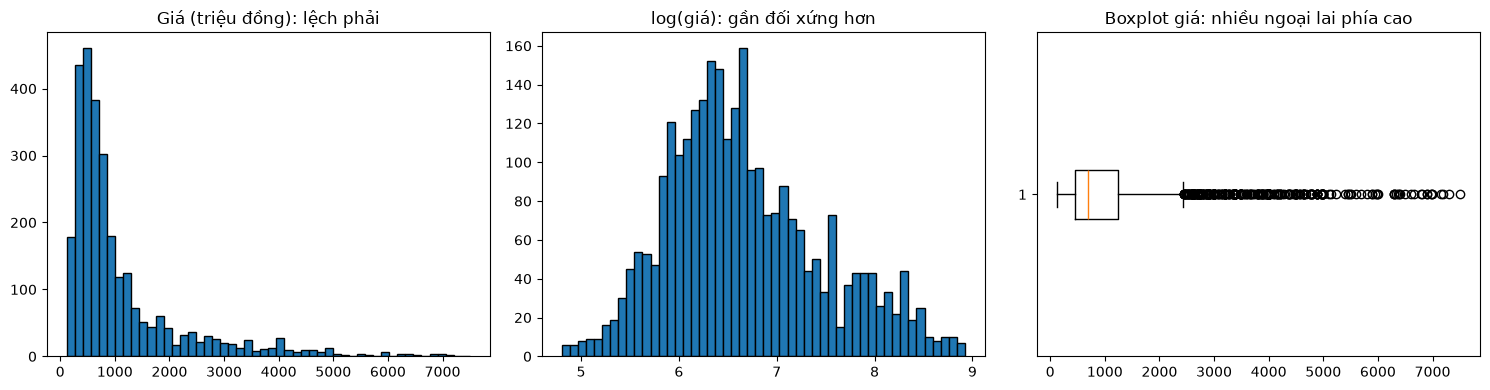

Độ lệch (skewness) của giá: 2.4 | của log(giá): 0.54
Trung bình: 1116 | trung vị: 696 (trung bình bị xe sang kéo lên)


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(clean[TARGET], bins=50, edgecolor="k"); ax[0].set_title("Giá (triệu đồng): lệch phải")
ax[1].hist(np.log(clean[TARGET]), bins=50, edgecolor="k"); ax[1].set_title("log(giá): gần đối xứng hơn")
ax[2].boxplot(clean[TARGET], vert=False); ax[2].set_title("Boxplot giá: nhiều ngoại lai phía cao")
plt.tight_layout(); plt.show()
print("Độ lệch (skewness) của giá:", round(clean[TARGET].skew(), 2), "| của log(giá):", round(np.log(clean[TARGET]).skew(), 2))
print("Trung bình:", round(clean[TARGET].mean()), "| trung vị:", round(clean[TARGET].median()), "(trung bình bị xe sang kéo lên)")

**Vì sao dùng log(giá)?**
1. Giá lệch phải, vài xe rất đắt chi phối các độ đo như RMSE.
2. Ảnh hưởng của các yếu tố lên giá mang tính **nhân** (xe đắt hơn mất giá tuyệt đối nhiều hơn nhưng cùng tỉ lệ %), và log biến phép nhân thành phép cộng, phù hợp mô hình tuyến tính.
3. Sai số theo tỉ lệ % (nhầm 50 triệu với xe 300 triệu khác với xe 3 tỉ) mới đúng với cảm nhận người dùng.

## 4. Giá phụ thuộc vào tuổi xe và số km thế nào

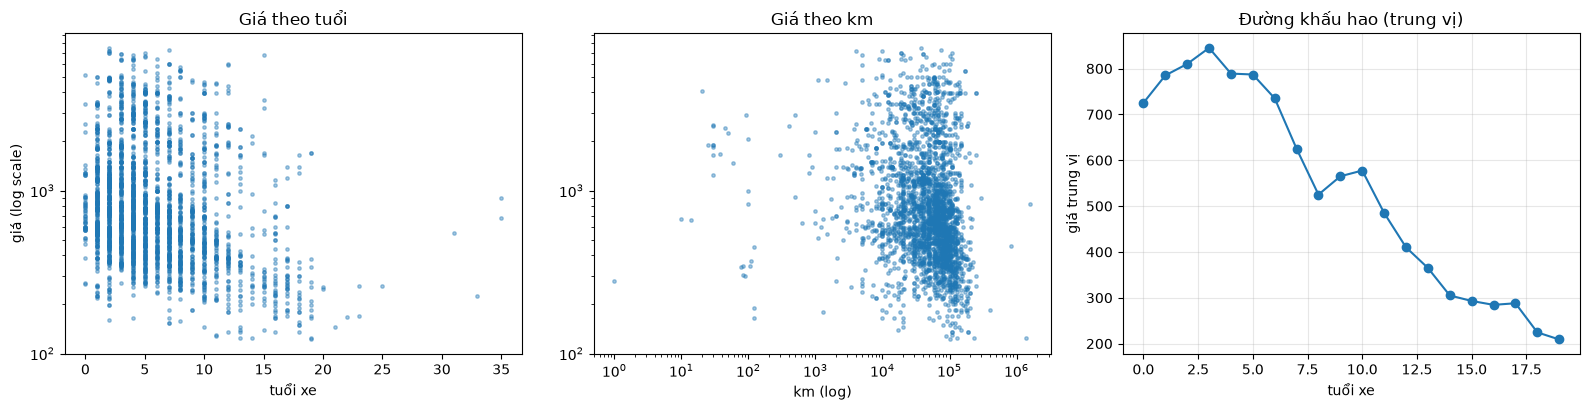

Mức giảm giá trung vị mỗi năm (%):
age
1      8.3
2      3.2
3      4.3
4     -6.6
5     -0.3
6     -6.6
7    -15.0
8    -16.0
9      7.6
10     2.2
11   -16.0
12   -15.5
13   -11.0
14   -16.4
15    -3.9
16    -2.9
17     1.2
18   -22.0
19    -6.9


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].scatter(clean["age"], clean[TARGET], s=6, alpha=.4); ax[0].set_yscale("log"); ax[0].set_xlabel("tuổi xe"); ax[0].set_ylabel("giá (log scale)")
ax[0].set_title("Giá theo tuổi")
ax[1].scatter(clean["km"], clean[TARGET], s=6, alpha=.4); ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("km (log)"); ax[1].set_title("Giá theo km")
med = clean.groupby("age")[TARGET].agg(["median", "count"]); med = med[med["count"] >= 10]
ax[2].plot(med.index, med["median"], "o-"); ax[2].set_xlabel("tuổi xe"); ax[2].set_ylabel("giá trung vị"); ax[2].set_title("Đường khấu hao (trung vị)"); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

dep = med["median"].pct_change().dropna()
print("Mức giảm giá trung vị mỗi năm (%):"); print((dep * 100).round(1).to_string())

**Suy nghĩ:** xu hướng chung là giảm theo tuổi, nhưng đường trung vị khá **nhiễu** (có năm giá còn tăng) vì cơ cấu hãng thay đổi theo tuổi: xe cũ chủ yếu là hãng phổ thông giá rẻ, xe sang thường mới. Đây là lý do cần mô hình nhiều biến thay vì nhìn một biến riêng lẻ. Vì sao `log(giá)` giúp quan hệ với tuổi gần thẳng hơn?

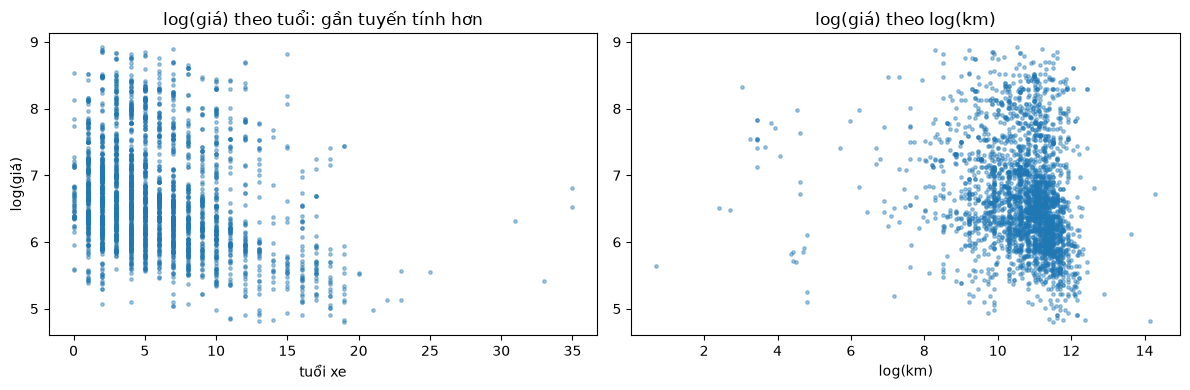

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(clean["age"], np.log(clean[TARGET]), s=6, alpha=.4); ax[0].set_xlabel("tuổi xe"); ax[0].set_ylabel("log(giá)"); ax[0].set_title("log(giá) theo tuổi: gần tuyến tính hơn")
ax[1].scatter(np.log(clean["km"] + 1), np.log(clean[TARGET]), s=6, alpha=.4); ax[1].set_xlabel("log(km)"); ax[1].set_title("log(giá) theo log(km)")
plt.tight_layout(); plt.show()

## 5. Giá theo hãng và các thuộc tính phân loại

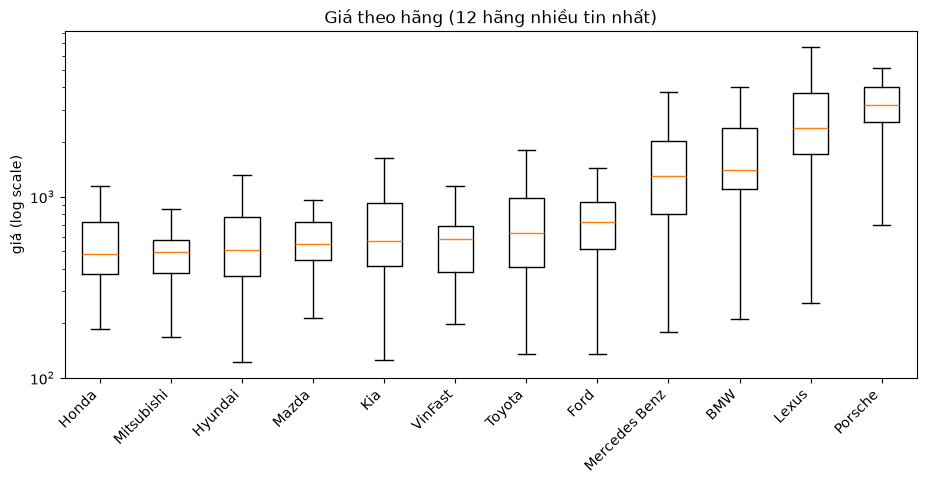

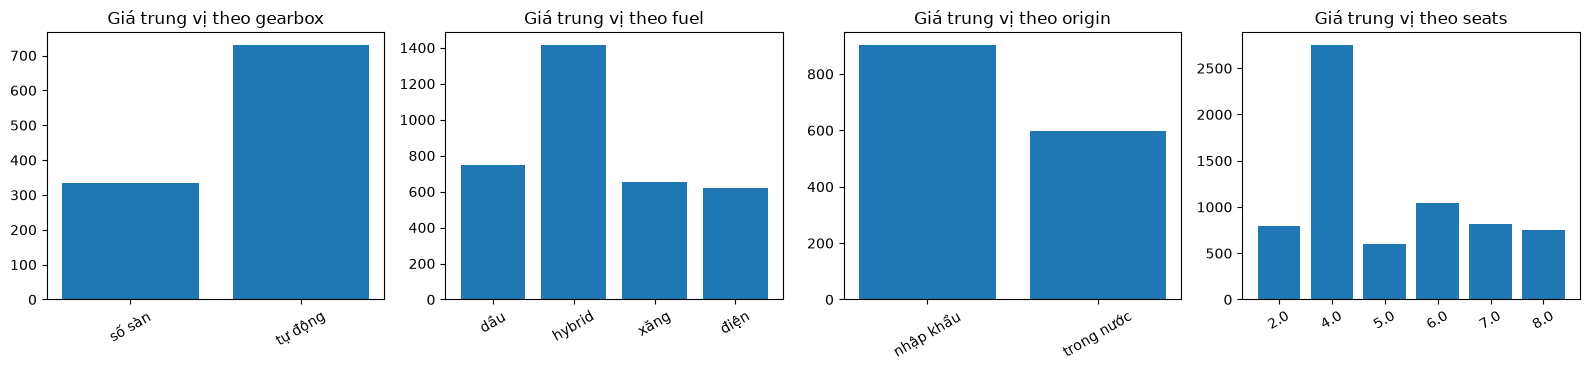

In [9]:
top = clean["brand"].value_counts().head(12).index
order = clean[clean["brand"].isin(top)].groupby("brand")[TARGET].median().sort_values().index
plt.figure(figsize=(11, 4.5))
plt.boxplot([clean.loc[clean["brand"] == b, TARGET] for b in order], tick_labels=order, orientation="vertical", showfliers=False)
plt.yscale("log"); plt.xticks(rotation=45, ha="right"); plt.ylabel("giá (log scale)"); plt.title("Giá theo hãng (12 hãng nhiều tin nhất)"); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for a, col in zip(ax, ["gearbox", "fuel", "origin", "seats"]):
    g = clean.groupby(col)[TARGET].agg(["median", "count"]); g = g[g["count"] >= 15]
    a.bar(g.index.astype(str), g["median"]); a.set_title(f"Giá trung vị theo {col}"); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

In [10]:
prov = clean.groupby("province")[TARGET].agg(["median", "count"]).sort_values("count", ascending=False).head(10)
display(prov.round(0))
print("Tỉnh chiếm bao nhiêu % số tin?", (clean["province"].value_counts(normalize=True).head(3) * 100).round(1).to_dict())

,median,count
province,,
Hà Nội,740.0,1618
TP HCM,820.0,730
Bình Dương,537.0,66
Hải Phòng,509.0,63
Đăk Lăk,480.0,49
Đồng Nai,440.0,33
Đà Nẵng,592.0,32
Phú Thọ,550.0,29
Lâm Đồng,425.0,27


Tỉnh chiếm bao nhiêu % số tin? {'Hà Nội': 56.8, 'TP HCM': 25.6, 'Bình Dương': 2.3}


**Chú ý:** hai thuộc tính có thể "giả" tương quan với giá. Ví dụ xe điện giá cao có thể do hãng (VinFast) hoặc do xe mới, không hẳn do loại nhiên liệu. Khi mô hình tuyến tính cùng xét nhiều biến, ta mới tách được ảnh hưởng riêng (`02_hoi_quy_tuyen_tinh`).

## 6. Tương quan và đa cộng tuyến

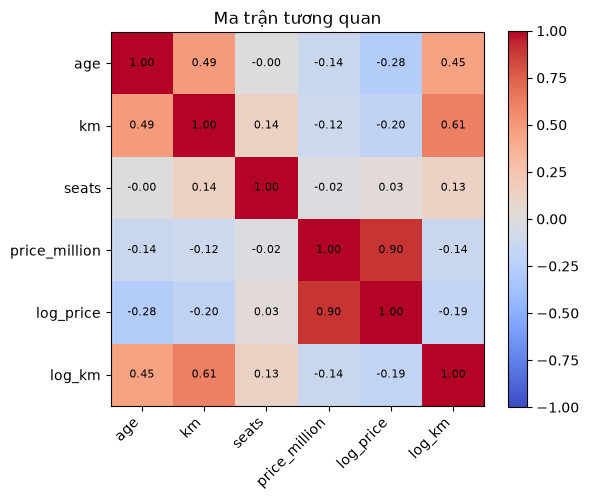

In [11]:
num = clean[["age", "km", "seats", TARGET]].assign(log_price=np.log(clean[TARGET]), log_km=np.log1p(clean["km"]))
corr = num.corr()
plt.figure(figsize=(6, 5)); plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1); plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right"); plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)): plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Ma trận tương quan"); plt.tight_layout(); plt.show()

`age` và `km` tương quan mạnh (xe càng cũ đi càng nhiều). Đó là **đa cộng tuyến**: mô hình tuyến tính khó tách ảnh hưởng riêng của từng biến, hệ số có thể thiếu ổn định. Mô hình cây ít bị ảnh hưởng hơn.

## 7. Phát hiện bất thường

In [12]:
print("Xe đắt nhất:"); display(clean.nlargest(5, TARGET)[["brand", "model", "year", "km", "price_million"]])
print("Xe rẻ nhất:");  display(clean.nsmallest(5, TARGET)[["brand", "model", "year", "km", "price_million"]])

# Xe mới nhưng đã đi rất nhiều km, hoặc xe cũ nhưng đi rất ít: đáng ngờ
clean["km_per_year"] = clean["km"] / (clean["age"].clip(lower=1))
print("Số km trung bình mỗi năm: trung vị =", round(clean["km_per_year"].median()), "| bách phân vị 99% =", round(clean["km_per_year"].quantile(.99)))
display(clean.nlargest(5, "km_per_year")[["brand", "model", "year", "km", "km_per_year", "price_million"]])

Xe đắt nhất:


,brand,model,year,km,price_million
2593,Lexus,LX,2024,37000.0,7500.0
139,Lexus,LX,2019,74000.0,7299.0
1195,Lexus,LX,2024,10000.0,7200.0
2461,Porsche,Panamera,2024,4000.0,7150.0
178,Porsche,Panamera,2024,19000.0,6999.0


Xe rẻ nhất:


,brand,model,year,km,price_million
215,Hyundai,Getz,2007,100000.0,122.0
12,Chevrolet,Spark,2013,1400000.0,124.0
868,Kia,Morning,2012,130000.0,125.0
1223,Kia,Morning,2007,234567.0,125.0
1636,Hyundai,i10,2015,90000.0,128.0


Số km trung bình mỗi năm: trung vị = 11000 | bách phân vị 99% = 47000


,brand,model,year,km,km_per_year,price_million
2306,Mitsubishi,Xpander,2022,820000.0,205000.000000,455.0
2670,Audi,Q7,2016,1600000.0,160000.000000,830.0
2672,VinFast,VF5,2025,130000.0,130000.000000,340.0
12,Chevrolet,Spark,2013,1400000.0,107692.307692,124.0
1932,Mazda,CX8,2025,80000.0,80000.000000,725.0


## 8. Tóm tắt những gì rút ra

- Giá lệch phải mạnh, dùng `log(giá)` và đánh giá bằng **sai số %**.
- Giá giảm theo tuổi và theo số km nhưng đường trung vị nhiễu do cơ cấu hãng; hãng xe là yếu tố rất lớn.
- `age` và `km` tương quan mạnh, cần để ý khi diễn giải hệ số.
- Tin thiếu km bị loại; cần ghi lại điều này như một hạn chế.

## Bài tập
1. Tính phần trăm tin bị loại ở mỗi bước làm sạch. Bước nào loại nhiều nhất?
2. Vẽ giá trung vị theo `province`. Khác biệt giữa Hà Nội và TP.HCM có ý nghĩa không? (Gợi ý: so sánh sau khi kiểm soát hãng xe.)
3. Tạo cột `km_per_year` và kiểm tra nó có giải thích thêm giá không.
4. Tìm 5 tin có giá bất thường so với các xe cùng hãng, cùng đời. Bạn đoán nguyên nhân là gì?
5. Thử loại ngoại lai bằng khoảng 1,5×IQR thay vì phân vị 0,5%; kết quả khác ra sao?